# Q7 Practice: SuperTrend + RiskParity Robustness Validation

Q7 的目标不是继续优化收益，而是验证 Q6 里最有潜力也最可疑的候选：`SuperTrend + RiskParity`。

固定基准仍然是原三资产 RiskParity：

- `510300.SS`: 沪深300 ETF
- `513100.SS`: 纳指100 ETF
- `518880.SS`: 黄金 ETF

本 notebook 重点回答：SuperTrend overlay 是否能经受滚动子样本、样本外、成本滑点、执行方式、参数网格和资产角色调整的检查；以及 Q8 是否值得进入 BTC 验证。


## 1. Setup and Data Loading

所有策略使用相同三资产、相同日线数据、相同再平衡频率。信号在收盘后生成，默认在下一交易日收盘收益中生效；另设 next-open 执行版本做保守检查。


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q7-supertrend-riskparity-robustness")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SYMBOLS = ("510300.SS", "513100.SS", "518880.SS")
EQUITY_SYMBOLS = ("510300.SS", "513100.SS")
GOLD_SYMBOL = "518880.SS"
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "518880.SS": "黄金ETF",
}
START = "2016-06-21"
INITIAL_CAPITAL = 100_000
TRADING_DAYS = 252
REBALANCE_DAYS = 10
VOL_WINDOW = 20
BASE_ATR = 10
BASE_MULTIPLIER = 3.0
PARAM_GRID = [(atr, mult) for atr in [7, 10, 14] for mult in [2.0, 3.0, 4.0]]


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol, start=START):
    df = yf.download(symbol, start=start, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["open", "high", "low", "close"])
    df.index = pd.DatetimeIndex(df.index).tz_localize(None)
    return df

raw_data = {sym: download_symbol(sym) for sym in SYMBOLS}
common_index = raw_data[SYMBOLS[0]].index
for sym in SYMBOLS[1:]:
    common_index = common_index.intersection(raw_data[sym].index)
common_index = common_index.sort_values()

data = {sym: raw_data[sym].reindex(common_index).dropna(subset=["close"]) for sym in SYMBOLS}
close = pd.DataFrame({sym: data[sym]["close"] for sym in SYMBOLS}).dropna()
open_ = pd.DataFrame({sym: data[sym]["open"] for sym in SYMBOLS}).reindex(close.index)
high = pd.DataFrame({sym: data[sym]["high"] for sym in SYMBOLS}).reindex(close.index)
low = pd.DataFrame({sym: data[sym]["low"] for sym in SYMBOLS}).reindex(close.index)
returns_cc = close.pct_change().fillna(0.0)
gap_returns = (open_ / close.shift(1) - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)
intraday_returns = (close / open_ - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)

print(f"共同样本: {close.index[0].date()} 到 {close.index[-1].date()}，{len(close)} 个交易日")
for sym in SYMBOLS:
    print(f"{SYMBOL_NAMES[sym]}: {close[sym].iloc[-1] / close[sym].iloc[0] - 1:.2%}")


共同样本: 2016-06-21 到 2026-06-22，2425 个交易日
沪深300ETF: 94.85%
纳指100ETF: 627.68%
黄金ETF: 221.39%


## 2. Backtest Helpers

为了做成本和执行方式检查，这里不只保存净值，也保存目标权重、实际持仓权重、换手率和成本。


In [3]:
def normalize_weights(w):
    weights = {sym: float(max(0.0, w.get(sym, 0.0))) for sym in SYMBOLS}
    total = sum(weights.values())
    if total > 1.0 + 1e-12:
        weights = {sym: val / total for sym, val in weights.items()}
        total = 1.0
    weights["CASH"] = max(0.0, 1.0 - total)
    return weights


def risk_parity_weight(date, eligible, vol_window=VOL_WINDOW):
    eligible = list(eligible)
    if not eligible:
        return normalize_weights({})
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({})
    hist = returns_cc.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({})
    inv = 1.0 / vols
    return normalize_weights((inv / inv.sum()).to_dict())


def all_assets_selector(_date):
    return list(SYMBOLS)


def make_rebalance_mask(index, every=REBALANCE_DAYS):
    mask = pd.Series(False, index=index)
    mask.iloc[::every] = True
    return mask


def build_target_weights(selector, vol_window=VOL_WINDOW, rebalance_days=REBALANCE_DAYS):
    rebalance_mask = make_rebalance_mask(close.index, rebalance_days)
    rows = []
    last = normalize_weights({})
    for date in close.index:
        if bool(rebalance_mask.loc[date]):
            last = risk_parity_weight(date, selector(date), vol_window)
        rows.append(last)
    targets = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(SYMBOLS) + ["CASH"]:
        if col not in targets.columns:
            targets[col] = 0.0
    return targets[list(SYMBOLS) + ["CASH"]]


def backtest_targets(name, targets, execution="next_close", cost_bps=0.0):
    cost_rate = cost_bps / 10_000.0
    dates = close.index
    prev_weights = pd.Series(0.0, index=list(SYMBOLS) + ["CASH"])
    current_weights = prev_weights.copy()
    nav = []
    rets = []
    turnover = []
    costs = []
    held_rows = []
    value = INITIAL_CAPITAL

    for i, date in enumerate(dates):
        desired = targets.iloc[i - 1] if i > 0 else prev_weights
        desired = desired.reindex(prev_weights.index).fillna(0.0)

        if execution == "next_close":
            trade = (desired - current_weights).abs().sum() / 2.0
            gross = float((desired[list(SYMBOLS)] * returns_cc.loc[date, list(SYMBOLS)]).sum())
            cost = trade * cost_rate
            current_weights = desired.copy()
            day_ret = gross - cost
        elif execution == "next_open":
            # From yesterday's close to today's open, old weights are still held.
            gap = float((current_weights[list(SYMBOLS)] * gap_returns.loc[date, list(SYMBOLS)]).sum())
            value_after_gap = value * (1.0 + gap)
            trade = (desired - current_weights).abs().sum() / 2.0
            cost_cash = value_after_gap * trade * cost_rate
            value_after_trade = value_after_gap - cost_cash
            intraday = float((desired[list(SYMBOLS)] * intraday_returns.loc[date, list(SYMBOLS)]).sum())
            new_value = value_after_trade * (1.0 + intraday)
            day_ret = new_value / value - 1.0 if value > 0 else 0.0
            cost = cost_cash / value if value > 0 else 0.0
            current_weights = desired.copy()
        else:
            raise ValueError(f"Unknown execution: {execution}")

        value *= (1.0 + day_ret)
        nav.append(value)
        rets.append(day_ret)
        turnover.append(float(trade))
        costs.append(float(cost))
        held_rows.append(current_weights.to_dict())

    return {
        "name": name,
        "nav": pd.Series(nav, index=dates, name=name),
        "returns": pd.Series(rets, index=dates, name=name),
        "targets": targets,
        "weights": pd.DataFrame(held_rows, index=dates).fillna(0.0),
        "turnover": pd.Series(turnover, index=dates, name=name),
        "costs": pd.Series(costs, index=dates, name=name),
        "execution": execution,
        "cost_bps": cost_bps,
    }


def run_rp(name="原三资产RiskParity", execution="next_close", cost_bps=0.0, vol_window=VOL_WINDOW):
    targets = build_target_weights(all_assets_selector, vol_window=vol_window)
    return backtest_targets(name, targets, execution=execution, cost_bps=cost_bps)


In [4]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=BASE_ATR, multiplier=BASE_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr

    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)

    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue

        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]

        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish


_SUPERTREND_CACHE = {}

def supertrend_matrix(atr_period=BASE_ATR, multiplier=BASE_MULTIPLIER):
    key = (atr_period, float(multiplier))
    if key in _SUPERTREND_CACHE:
        return _SUPERTREND_CACHE[key]
    signals = {}
    lines = {}
    for sym in SYMBOLS:
        line, bull = supertrend_signal_for_symbol(sym, atr_period, multiplier)
        lines[sym] = line
        signals[sym] = bull
    result = (pd.DataFrame(signals), pd.DataFrame(lines))
    _SUPERTREND_CACHE[key] = result
    return result


def supertrend_selector(atr_period=BASE_ATR, multiplier=BASE_MULTIPLIER, mode="all_assets"):
    bull, _line = supertrend_matrix(atr_period, multiplier)
    def _selector(date):
        row = bull.loc[date]
        eligible = []
        for sym in SYMBOLS:
            if mode == "equities_only_gold_always" and sym == GOLD_SYMBOL:
                eligible.append(sym)
            elif bool(row.get(sym, False)):
                eligible.append(sym)
        return eligible
    return _selector


def run_supertrend_rp(name, atr_period=BASE_ATR, multiplier=BASE_MULTIPLIER, mode="all_assets", execution="next_close", cost_bps=0.0):
    selector = supertrend_selector(atr_period, multiplier, mode=mode)
    targets = build_target_weights(selector, vol_window=VOL_WINDOW)
    return backtest_targets(name, targets, execution=execution, cost_bps=cost_bps)

print("SuperTrend helpers ready")


SuperTrend helpers ready


## 3. Metric Helpers

指标沿用 Q3/Q5：收益、波动、最大回撤、Sharpe、Calmar、Sortino、月度结构、回撤事件、权重和换手。


In [5]:
def drawdown(nav_s):
    return nav_s / nav_s.cummax() - 1.0


def slice_result(result, start=None, end=None):
    nav = result["nav"].loc[start:end]
    ret = result["returns"].loc[start:end]
    weights = result["weights"].loc[start:end]
    turnover = result["turnover"].loc[start:end]
    costs = result["costs"].loc[start:end]
    if nav.empty:
        raise ValueError(f"Empty slice for {result['name']}: {start} to {end}")
    # Rebase NAV inside the period so period returns are comparable.
    nav = nav / nav.iloc[0] * INITIAL_CAPITAL
    return {**result, "nav": nav, "returns": ret, "weights": weights, "turnover": turnover, "costs": costs}


def strategy_metrics(result):
    nav_s = result["nav"].dropna()
    ret_s = result["returns"].reindex(nav_s.index).fillna(0.0)
    if len(nav_s) < 2:
        return {}
    total = nav_s.iloc[-1] / nav_s.iloc[0] - 1.0
    annual = (nav_s.iloc[-1] / nav_s.iloc[0]) ** (TRADING_DAYS / (len(nav_s) - 1)) - 1.0
    vol = ret_s.std(ddof=1) * np.sqrt(TRADING_DAYS)
    max_dd = drawdown(nav_s).min()
    sharpe = (ret_s.mean() * TRADING_DAYS) / vol if vol > 0 else np.nan
    calmar = annual / abs(max_dd) if max_dd < 0 else np.nan
    downside = ret_s[ret_s < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = (ret_s.mean() * TRADING_DAYS) / downside_dev if downside_dev and downside_dev > 0 else np.nan
    weights = result["weights"].reindex(nav_s.index).fillna(0.0)
    turnover = result["turnover"].reindex(nav_s.index).fillna(0.0)
    costs = result["costs"].reindex(nav_s.index).fillna(0.0)
    row = {
        "累计收益": total,
        "年化收益": annual,
        "年化波动": vol,
        "最大回撤": max_dd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
        "平均现金": weights["CASH"].mean() if "CASH" in weights else 0.0,
        "年化换手": turnover.mean() * TRADING_DAYS,
        "成本拖累": costs.sum(),
    }
    for sym in SYMBOLS:
        row[f"当前权重_{SYMBOL_NAMES[sym]}"] = weights[sym].iloc[-1]
        row[f"平均权重_{SYMBOL_NAMES[sym]}"] = weights[sym].mean()
    return row


def monthly_returns(nav_s):
    month_end = nav_s.resample("ME").last()
    return month_end.pct_change().dropna()


def annual_returns(nav_s):
    year_end = nav_s.resample("YE").last()
    prev = pd.concat([pd.Series([nav_s.iloc[0]], index=[nav_s.index[0]]), year_end])
    out = prev.pct_change().dropna()
    out.index = out.index.year
    return out


def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def monthly_stats(result):
    months = monthly_returns(result["nav"])
    gains = months[months > 0]
    losses = months[months < 0]
    total_gain = gains.sum()
    total_loss = losses.sum()
    avg_gain = gains.mean() if len(gains) else 0.0
    avg_loss = losses.mean() if len(losses) else 0.0
    return {
        "总月数": len(months),
        "盈利月数": len(gains),
        "亏损月数": len(losses),
        "月度胜率": len(gains) / len(months) if len(months) else np.nan,
        "平均盈利月": avg_gain,
        "平均亏损月": avg_loss,
        "盈亏比": avg_gain / abs(avg_loss) if avg_loss != 0 else np.nan,
        "盈亏因子": total_gain / abs(total_loss) if total_loss != 0 else np.nan,
        "最好月": months.max() if len(months) else np.nan,
        "最差月": months.min() if len(months) else np.nan,
        "最长连赢": max_consecutive(months > 0),
        "最长连亏": max_consecutive(months < 0),
    }


def drawdown_events(result):
    dd = drawdown(result["nav"]).dropna()
    events = []
    in_dd = False
    start = trough = None
    trough_value = 0.0
    for date, value in dd.items():
        if not in_dd and value < 0:
            in_dd = True
            start = trough = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough = date
                trough_value = value
            if value >= 0:
                events.append({
                    "开始日期": pd.Timestamp(start).date(),
                    "最低点日期": pd.Timestamp(trough).date(),
                    "恢复日期": pd.Timestamp(date).date(),
                    "深度": trough_value,
                    "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
                    "恢复天数": (pd.Timestamp(date) - pd.Timestamp(trough)).days,
                    "总持续天数": (pd.Timestamp(date) - pd.Timestamp(start)).days,
                })
                in_dd = False
                start = trough = None
                trough_value = 0.0
    if in_dd and start is not None:
        last = dd.index[-1]
        events.append({
            "开始日期": pd.Timestamp(start).date(),
            "最低点日期": pd.Timestamp(trough).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
            "恢复天数": np.nan,
            "总持续天数": (pd.Timestamp(last) - pd.Timestamp(start)).days,
        })
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def drawdown_summary(result):
    events = drawdown_events(result)
    if events.empty:
        return {"最大回撤": 0.0, "平均回撤深度": 0.0, "平均恢复天数": np.nan, "最长恢复天数": np.nan, "回撤次数": 0}
    recovered = events[pd.to_numeric(events["恢复天数"], errors="coerce").notna()].copy()
    return {
        "最大回撤": events["深度"].min(),
        "平均回撤深度": events["深度"].mean(),
        "平均恢复天数": recovered["恢复天数"].mean() if len(recovered) else np.nan,
        "最长恢复天数": recovered["恢复天数"].max() if len(recovered) else np.nan,
        "回撤次数": len(events),
    }


## 4. Full-Sample Baseline And Q7 Main Variants

Q7 不再扩展动量和 MA200，只保留围绕 SuperTrend overlay 的主线：

- 原三资产 RiskParity
- 全资产 SuperTrend + RiskParity
- 只过滤权益、黄金常驻 + RiskParity


In [6]:
main_results = {
    "原三资产RiskParity": run_rp("原三资产RiskParity"),
    "SuperTrend全资产+RiskParity": run_supertrend_rp("SuperTrend全资产+RiskParity", BASE_ATR, BASE_MULTIPLIER, mode="all_assets"),
    "SuperTrend权益过滤黄金常驻+RiskParity": run_supertrend_rp("SuperTrend权益过滤黄金常驻+RiskParity", BASE_ATR, BASE_MULTIPLIER, mode="equities_only_gold_always"),
}

q3_metrics = pd.DataFrame({name: strategy_metrics(result) for name, result in main_results.items()}).T
baseline_total = q3_metrics.loc["原三资产RiskParity", "累计收益"]
q5_metrics = q3_metrics[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺", "平均现金", "年化换手", "成本拖累"]].copy()
q5_metrics["Alpha_vs_RP基准"] = q5_metrics["累计收益"] - baseline_total
q5_metrics = q5_metrics.join(pd.DataFrame({name: monthly_stats(result) for name, result in main_results.items()}).T)
q3_metrics.to_csv(OUTPUT_DIR / "q3_metrics.csv", encoding="utf-8-sig")
q5_metrics.to_csv(OUTPUT_DIR / "q5_metrics.csv", encoding="utf-8-sig")
pd.DataFrame({name: result["weights"].iloc[-1] for name, result in main_results.items()}).T.to_csv(OUTPUT_DIR / "latest_weights.csv", encoding="utf-8-sig")
pd.DataFrame({name: result["weights"].mean() for name, result in main_results.items()}).T.to_csv(OUTPUT_DIR / "average_weights.csv", encoding="utf-8-sig")

q5_metrics.round(4)


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,平均现金,年化换手,成本拖累,...,亏损月数,月度胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,最好月,最差月,最长连赢,最长连亏
原三资产RiskParity,3.1864,0.1605,0.1119,-0.1353,1.3863,1.1862,1.3090,0.0082,1.9821,0.0,...,42.0,0.6500,0.0278,-0.0162,1.7223,3.1985,0.0922,-0.0750,11.0,4.0
SuperTrend全资产+RiskParity,5.1478,0.2078,0.1348,-0.1838,1.4683,1.1308,1.3067,0.1237,10.9469,0.0,...,37.0,0.6750,0.0340,-0.0230,1.4805,3.2411,0.1365,-0.0732,11.0,3.0
SuperTrend权益过滤黄金常驻+RiskParity,4.2629,0.1884,0.1253,-0.2169,1.4408,0.8689,1.3381,0.0082,5.0909,0.0,...,31.0,0.7333,0.0271,-0.0212,1.2788,3.6302,0.0922,-0.1129,11.0,3.0


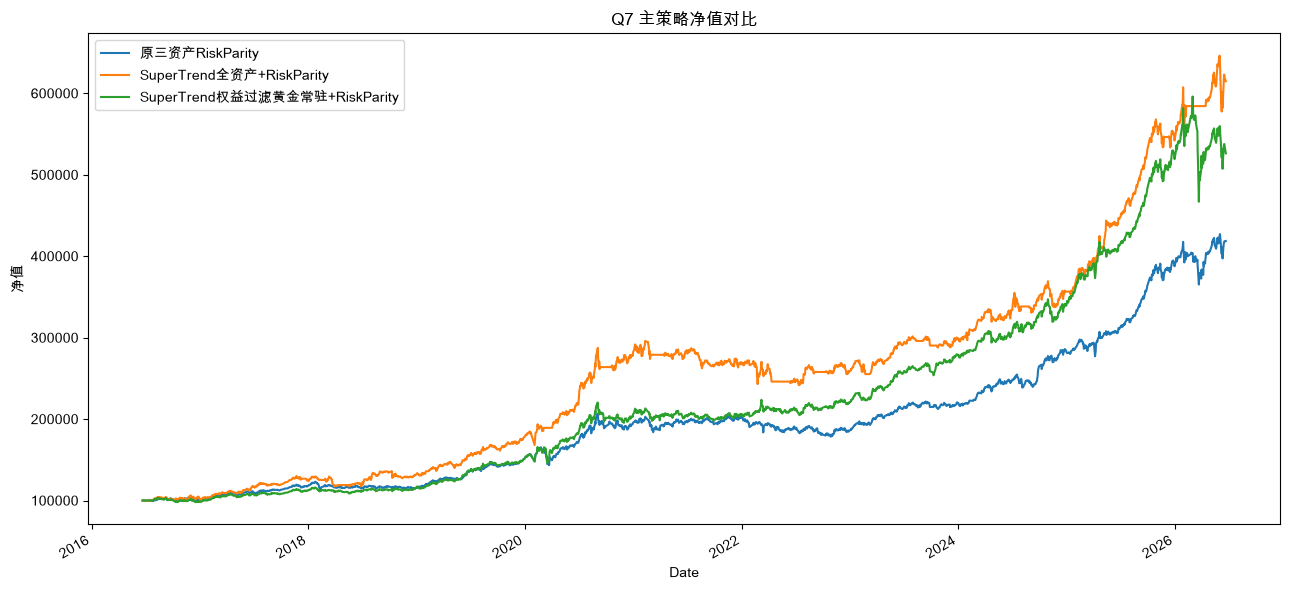

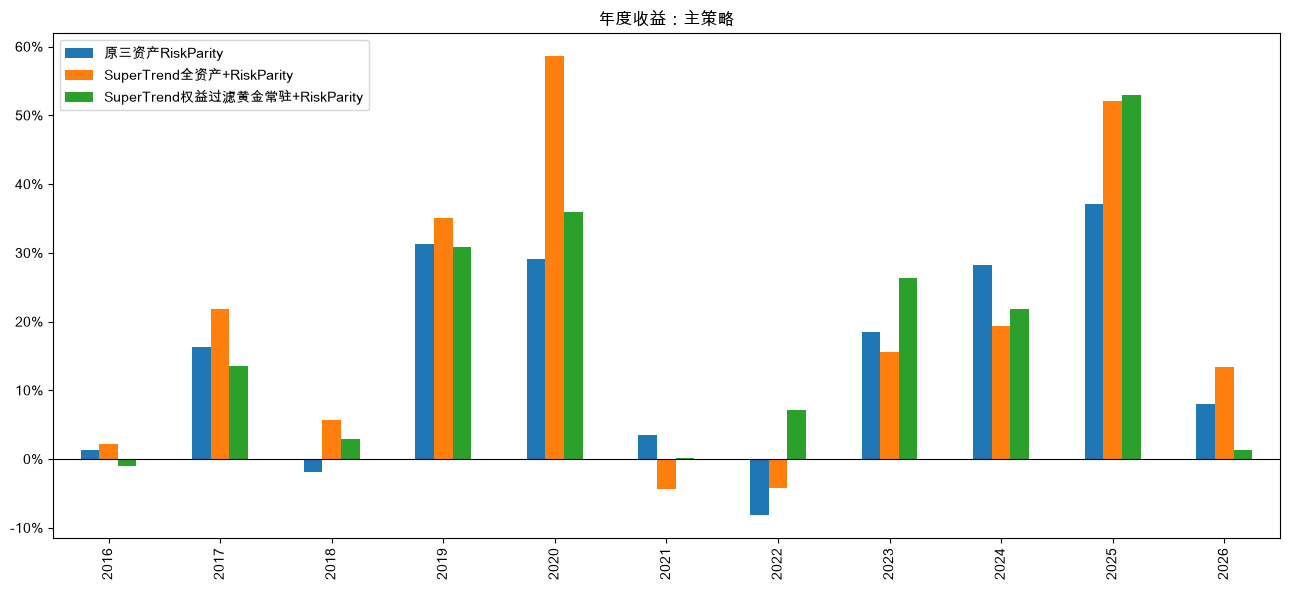

,原三资产RiskParity,SuperTrend全资产+RiskParity,SuperTrend权益过滤黄金常驻+RiskParity
2016,0.0131,0.0223,-0.0104
2017,0.1624,0.2189,0.1349
2018,-0.0193,0.0571,0.0297
2019,0.3121,0.3505,0.3087
2020,0.2911,0.5859,0.3600
2021,0.0348,-0.0440,0.0013
2022,-0.0819,-0.0416,0.0708
2023,0.1854,0.1556,0.2630
2024,0.2822,0.1936,0.2180
2025,0.3717,0.5203,0.5296


In [7]:
nav_table = pd.DataFrame({name: result["nav"] for name, result in main_results.items()})
nav_table.to_csv(OUTPUT_DIR / "nav_main_variants.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(13, 6))
nav_table.plot(ax=ax)
ax.set_title("Q7 主策略净值对比")
ax.set_ylabel("净值")
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_main_variants.png", dpi=160)
plt.show()

annual_table = pd.DataFrame({name: annual_returns(result["nav"]) for name, result in main_results.items()})
annual_table.to_csv(OUTPUT_DIR / "annual_returns.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(13, 6))
annual_table.plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("年度收益：主策略")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "annual_returns.png", dpi=160)
plt.show()

monthly_table = pd.DataFrame({name: monthly_returns(result["nav"]) for name, result in main_results.items()})
monthly_table.to_csv(OUTPUT_DIR / "monthly_returns.csv", encoding="utf-8-sig")
pd.DataFrame({name: monthly_stats(result) for name, result in main_results.items()}).T.to_csv(OUTPUT_DIR / "monthly_stats.csv", encoding="utf-8-sig")

annual_table.round(4)


## 5. Drawdown Events And Underwater Curves


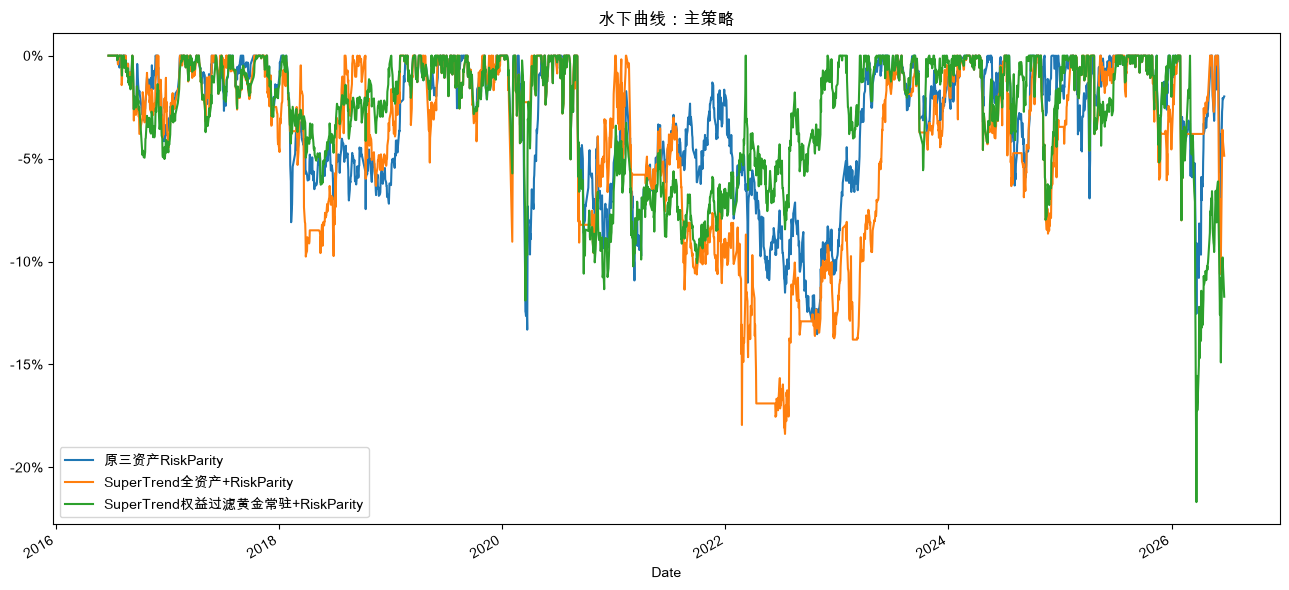

,最大回撤,平均回撤深度,平均恢复天数,最长恢复天数,回撤次数
原三资产RiskParity,-0.1353,-0.0152,12.4044,376.0,137.0
SuperTrend全资产+RiskParity,-0.1838,-0.0174,12.9783,363.0,139.0
SuperTrend权益过滤黄金常驻+RiskParity,-0.2169,-0.0156,12.8258,463.0,156.0


In [8]:
dd_summary = pd.DataFrame({name: drawdown_summary(result) for name, result in main_results.items()}).T
dd_summary.to_csv(OUTPUT_DIR / "drawdown_summary.csv", encoding="utf-8-sig")
for name, result in main_results.items():
    events = drawdown_events(result)
    events.head(10).to_csv(OUTPUT_DIR / f"drawdown_events_{name}.csv", encoding="utf-8-sig", index=False)

underwater = nav_table.apply(drawdown)
underwater.to_csv(OUTPUT_DIR / "underwater_curves.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(13, 6))
underwater.plot(ax=ax)
ax.set_title("水下曲线：主策略")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_curves.png", dpi=160)
plt.show()

dd_summary.round(4)


## 6. Rolling Subperiod Validation

滚动窗口用来检查 SuperTrend 是否只靠一两个年份撑起全样本。这里使用多个自然年份窗口，比较每个窗口里 SuperTrend 是否跑赢原 RiskParity，以及回撤是否恶化。


In [9]:
windows = [
    ("2016H2-2020", "2016-06-21", "2020-12-31"),
    ("2017-2021", "2017-01-01", "2021-12-31"),
    ("2018-2022", "2018-01-01", "2022-12-31"),
    ("2019-2023", "2019-01-01", "2023-12-31"),
    ("2020-2024", "2020-01-01", "2024-12-31"),
    ("2021-2025", "2021-01-01", "2025-12-31"),
    ("2022-YTD", "2022-01-01", str(close.index[-1].date())),
]
rolling_rows = []
for label, start, end in windows:
    rows = {}
    for name, result in main_results.items():
        sliced = slice_result(result, start, end)
        rows[name] = strategy_metrics(sliced)
    rp = rows["原三资产RiskParity"]
    for name, row in rows.items():
        out = dict(row)
        out["窗口"] = label
        out["策略"] = name
        out["超额收益_vs_RP"] = row["累计收益"] - rp["累计收益"]
        out["回撤差_vs_RP"] = row["最大回撤"] - rp["最大回撤"]
        out["Sharpe差_vs_RP"] = row["夏普"] - rp["夏普"]
        rolling_rows.append(out)
rolling_validation = pd.DataFrame(rolling_rows)
rolling_validation.to_csv(OUTPUT_DIR / "rolling_window_metrics.csv", encoding="utf-8-sig", index=False)

rolling_pivot = rolling_validation.pivot(index="窗口", columns="策略", values="累计收益")
rolling_pivot.to_csv(OUTPUT_DIR / "rolling_window_total_return_pivot.csv", encoding="utf-8-sig")

win_rows = []
for label in rolling_pivot.index:
    rp_ret = rolling_validation[(rolling_validation["窗口"] == label) & (rolling_validation["策略"] == "原三资产RiskParity")]["累计收益"].iloc[0]
    rp_dd = rolling_validation[(rolling_validation["窗口"] == label) & (rolling_validation["策略"] == "原三资产RiskParity")]["最大回撤"].iloc[0]
    for candidate in ["SuperTrend全资产+RiskParity", "SuperTrend权益过滤黄金常驻+RiskParity"]:
        cand = rolling_validation[(rolling_validation["窗口"] == label) & (rolling_validation["策略"] == candidate)].iloc[0]
        win_rows.append({
            "窗口": label,
            "候选": candidate,
            "收益跑赢RP": cand["累计收益"] > rp_ret,
            "Sharpe跑赢RP": cand["夏普"] > rolling_validation[(rolling_validation["窗口"] == label) & (rolling_validation["策略"] == "原三资产RiskParity")]["夏普"].iloc[0],
            "回撤不深于RP": cand["最大回撤"] >= rp_dd,
            "超额收益_vs_RP": cand["累计收益"] - rp_ret,
            "回撤差_vs_RP": cand["最大回撤"] - rp_dd,
            "Sharpe差_vs_RP": cand["夏普"] - rolling_validation[(rolling_validation["窗口"] == label) & (rolling_validation["策略"] == "原三资产RiskParity")]["夏普"].iloc[0],
        })
rolling_scorecard = pd.DataFrame(win_rows)
rolling_scorecard.to_csv(OUTPUT_DIR / "rolling_window_scorecard.csv", encoding="utf-8-sig", index=False)

rolling_scorecard


,窗口,候选,收益跑赢RP,Sharpe跑赢RP,回撤不深于RP,超额收益_vs_RP,回撤差_vs_RP,Sharpe差_vs_RP
0,2016H2-2020,SuperTrend全资产+RiskParity,True,True,True,0.864458,0.035487,0.364226
1,2016H2-2020,SuperTrend权益过滤黄金常驻+RiskParity,True,True,True,0.101391,0.014126,0.051914
2,2017-2021,SuperTrend全资产+RiskParity,True,True,True,0.661263,0.019418,0.178714
3,2017-2021,SuperTrend权益过滤黄金常驻+RiskParity,True,True,True,0.093547,0.014126,0.029801
4,2018-2022,SuperTrend全资产+RiskParity,True,True,False,0.514505,-0.048453,0.237867
5,2018-2022,SuperTrend权益过滤黄金常驻+RiskParity,True,True,True,0.389452,0.016345,0.363060
6,2019-2023,SuperTrend全资产+RiskParity,True,True,False,0.349338,-0.048453,0.077249
7,2019-2023,SuperTrend权益过滤黄金常驻+RiskParity,True,True,True,0.490782,0.016345,0.351822
8,2020-2024,SuperTrend全资产+RiskParity,True,False,False,0.138753,-0.048453,-0.055781
9,2020-2024,SuperTrend权益过滤黄金常驻+RiskParity,True,True,True,0.375606,0.016345,0.259716


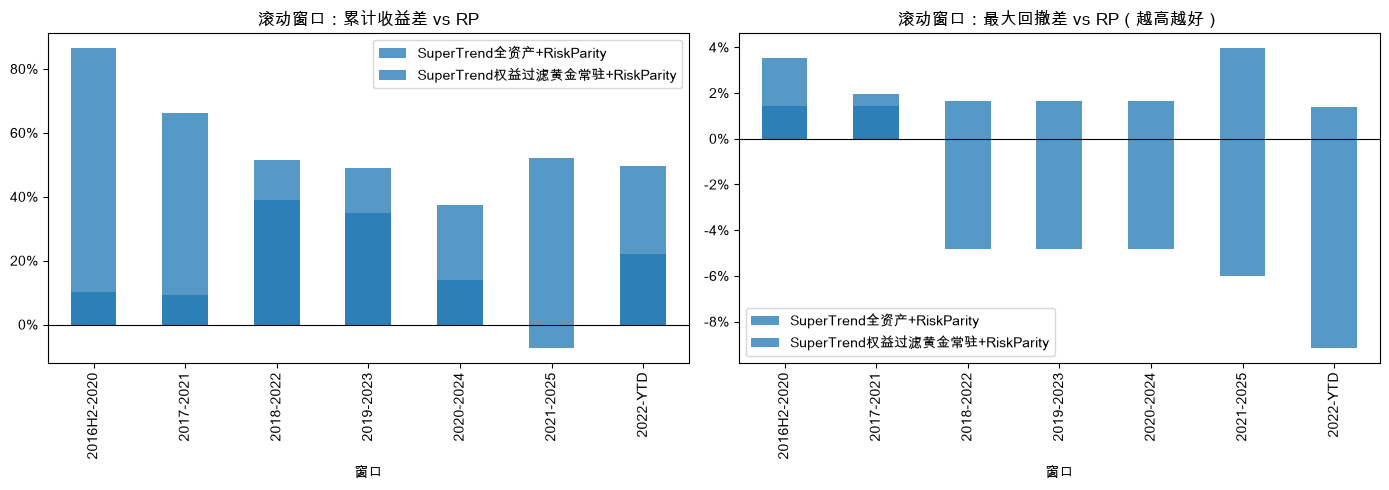

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for candidate in ["SuperTrend全资产+RiskParity", "SuperTrend权益过滤黄金常驻+RiskParity"]:
    sub = rolling_scorecard[rolling_scorecard["候选"] == candidate].set_index("窗口")
    sub["超额收益_vs_RP"].plot(kind="bar", ax=axes[0], alpha=0.75, label=candidate)
    sub["回撤差_vs_RP"].plot(kind="bar", ax=axes[1], alpha=0.75, label=candidate)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("滚动窗口：累计收益差 vs RP")
axes[0].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("滚动窗口：最大回撤差 vs RP（越高越好）")
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
for ax in axes:
    ax.legend(loc="best")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rolling_window_scorecard.png", dpi=160)
plt.show()


## 7. Explicit Out-Of-Sample Parameter Check

这里不是为了挑最优参数，而是检查参数稳定性。用 2016-2021 作为观察期，看小网格里训练期表现好的参数，在 2022-当前是否仍然有优势。


In [11]:
train_start, train_end = "2016-06-21", "2021-12-31"
test_start, test_end = "2022-01-01", str(close.index[-1].date())
param_results = {}
param_rows = []
for atr, mult in PARAM_GRID:
    name = f"ST_ATR{atr}_M{mult:g}+RP"
    result = run_supertrend_rp(name, atr, mult, mode="all_assets")
    param_results[(atr, mult)] = result
    train_metrics = strategy_metrics(slice_result(result, train_start, train_end))
    test_metrics = strategy_metrics(slice_result(result, test_start, test_end))
    full_metrics = strategy_metrics(result)
    param_rows.append({
        "atr": atr,
        "multiplier": mult,
        "策略": name,
        "train_累计收益": train_metrics["累计收益"],
        "train_夏普": train_metrics["夏普"],
        "train_最大回撤": train_metrics["最大回撤"],
        "test_累计收益": test_metrics["累计收益"],
        "test_夏普": test_metrics["夏普"],
        "test_最大回撤": test_metrics["最大回撤"],
        "full_累计收益": full_metrics["累计收益"],
        "full_夏普": full_metrics["夏普"],
        "full_最大回撤": full_metrics["最大回撤"],
    })
param_oos = pd.DataFrame(param_rows)
param_oos["train_夏普排名"] = param_oos["train_夏普"].rank(ascending=False, method="min")
param_oos["test_夏普排名"] = param_oos["test_夏普"].rank(ascending=False, method="min")
param_oos["test_收益排名"] = param_oos["test_累计收益"].rank(ascending=False, method="min")
param_oos.to_csv(OUTPUT_DIR / "parameter_oos_grid.csv", encoding="utf-8-sig", index=False)

train_best = param_oos.sort_values("train_夏普", ascending=False).iloc[0]
default_row = param_oos[(param_oos["atr"] == BASE_ATR) & (param_oos["multiplier"] == BASE_MULTIPLIER)].iloc[0]
rp_train = strategy_metrics(slice_result(main_results["原三资产RiskParity"], train_start, train_end))
rp_test = strategy_metrics(slice_result(main_results["原三资产RiskParity"], test_start, test_end))
oos_summary = pd.DataFrame([
    {"策略": "原三资产RiskParity", "区间": "train", **rp_train},
    {"策略": "原三资产RiskParity", "区间": "test", **rp_test},
    {"策略": "默认ST10_3+RP", "区间": "train", **strategy_metrics(slice_result(param_results[(BASE_ATR, BASE_MULTIPLIER)], train_start, train_end))},
    {"策略": "默认ST10_3+RP", "区间": "test", **strategy_metrics(slice_result(param_results[(BASE_ATR, BASE_MULTIPLIER)], test_start, test_end))},
    {"策略": f"训练期最佳ST{int(train_best['atr'])}_{train_best['multiplier']:g}+RP", "区间": "train", **strategy_metrics(slice_result(param_results[(int(train_best['atr']), float(train_best['multiplier']))], train_start, train_end))},
    {"策略": f"训练期最佳ST{int(train_best['atr'])}_{train_best['multiplier']:g}+RP", "区间": "test", **strategy_metrics(slice_result(param_results[(int(train_best['atr']), float(train_best['multiplier']))], test_start, test_end))},
])
oos_summary.to_csv(OUTPUT_DIR / "oos_summary.csv", encoding="utf-8-sig", index=False)

print(f"训练期最佳参数: ATR={int(train_best['atr'])}, multiplier={train_best['multiplier']:g}")
param_oos.sort_values("train_夏普", ascending=False).round(4)


训练期最佳参数: ATR=10, multiplier=3


,atr,multiplier,策略,train_累计收益,train_夏普,train_最大回撤,test_累计收益,test_夏普,test_最大回撤,full_累计收益,full_夏普,full_最大回撤,train_夏普排名,test_夏普排名,test_收益排名
4,10,3.0,ST_ATR10_M3+RP,1.6970,1.4844,-0.1137,1.2940,1.4503,-0.1116,5.1478,1.4683,-0.1838,1.0,4.0,4.0
1,7,3.0,ST_ATR7_M3+RP,1.6775,1.4266,-0.1406,1.2790,1.4716,-0.1332,5.0635,1.4469,-0.1805,2.0,3.0,6.0
3,10,2.0,ST_ATR10_M2+RP,1.2948,1.2673,-0.1589,1.1855,1.3269,-0.1356,3.9836,1.2936,-0.1589,3.0,7.0,7.0
0,7,2.0,ST_ATR7_M2+RP,1.2130,1.2566,-0.1589,0.8926,1.0970,-0.1621,3.1619,1.1769,-0.1621,4.0,9.0,9.0
6,14,2.0,ST_ATR14_M2+RP,1.2409,1.2457,-0.1589,1.3470,1.4428,-0.1356,4.2262,1.3370,-0.1589,5.0,5.0,2.0
7,14,3.0,ST_ATR14_M3+RP,1.3022,1.2383,-0.1632,1.3261,1.3884,-0.2361,4.3213,1.3074,-0.2361,6.0,6.0,3.0
5,10,4.0,ST_ATR10_M4+RP,1.0797,1.0423,-0.2234,1.4020,1.5978,-0.1025,3.9775,1.2811,-0.2234,7.0,1.0,1.0
8,14,4.0,ST_ATR14_M4+RP,0.8627,0.8853,-0.2249,1.1186,1.2934,-0.1749,2.9464,1.0673,-0.2485,8.0,8.0,8.0
2,7,4.0,ST_ATR7_M4+RP,0.7882,0.8591,-0.1696,1.2932,1.5035,-0.1025,3.0859,1.1419,-0.1696,9.0,2.0,5.0


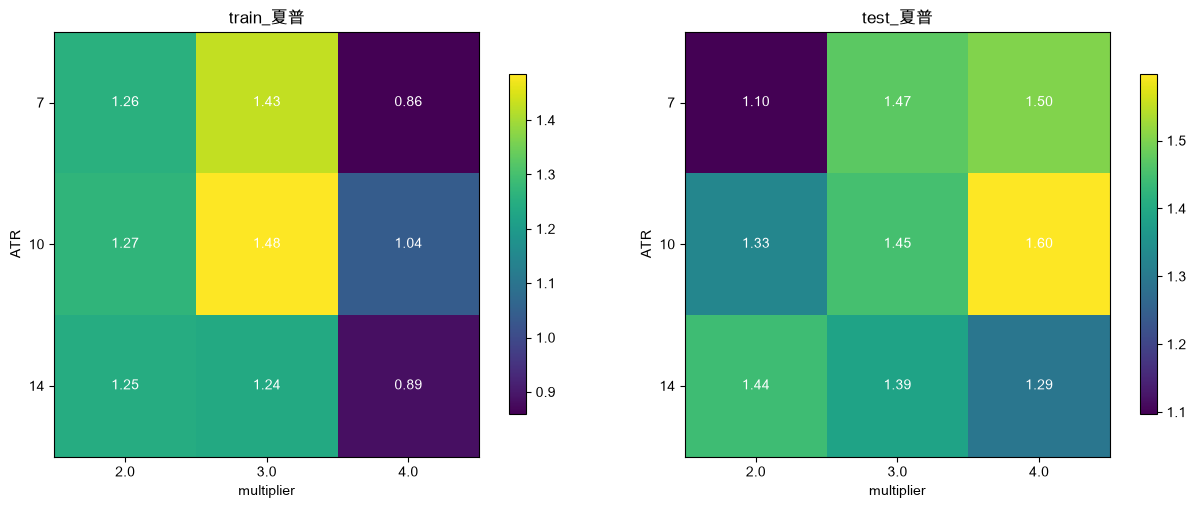

,策略,区间,累计收益,年化收益,最大回撤,夏普,卡玛
0,原三资产RiskParity,train,1.0248,0.1412,-0.1331,1.3132,1.0609
1,原三资产RiskParity,test,1.0732,0.1860,-0.1254,1.4723,1.4835
2,默认ST10_3+RP,train,1.6970,0.2041,-0.1137,1.4844,1.7956
3,默认ST10_3+RP,test,1.2940,0.2144,-0.1116,1.4503,1.9210
4,训练期最佳ST10_3+RP,train,1.6970,0.2041,-0.1137,1.4844,1.7956
5,训练期最佳ST10_3+RP,test,1.2940,0.2144,-0.1116,1.4503,1.9210


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for metric, ax in [("train_夏普", axes[0]), ("test_夏普", axes[1])]:
    pivot = param_oos.pivot(index="atr", columns="multiplier", values=metric)
    im = ax.imshow(pivot.values, cmap="viridis")
    ax.set_title(metric)
    ax.set_xticks(range(len(pivot.columns)), labels=[str(c) for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), labels=[str(i) for i in pivot.index])
    ax.set_xlabel("multiplier")
    ax.set_ylabel("ATR")
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", color="white")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "parameter_oos_heatmap.png", dpi=160)
plt.show()

oos_summary[["策略", "区间", "累计收益", "年化收益", "最大回撤", "夏普", "卡玛"]].round(4)


## 8. Transaction Cost And Execution Sensitivity

趋势过滤会提高换手，所以必须看成本。这里用单边成本 0/5/10/20 bps，并比较默认 next-close 与 next-open 执行。


In [13]:
cost_rows = []
for execution in ["next_close", "next_open"]:
    for cost_bps in [0, 5, 10, 20]:
        variants = {
            "原三资产RiskParity": run_rp("原三资产RiskParity", execution=execution, cost_bps=cost_bps),
            "SuperTrend全资产+RiskParity": run_supertrend_rp("SuperTrend全资产+RiskParity", BASE_ATR, BASE_MULTIPLIER, mode="all_assets", execution=execution, cost_bps=cost_bps),
            "SuperTrend权益过滤黄金常驻+RiskParity": run_supertrend_rp("SuperTrend权益过滤黄金常驻+RiskParity", BASE_ATR, BASE_MULTIPLIER, mode="equities_only_gold_always", execution=execution, cost_bps=cost_bps),
        }
        rp_total = strategy_metrics(variants["原三资产RiskParity"])["累计收益"]
        for name, result in variants.items():
            row = strategy_metrics(result)
            row["策略"] = name
            row["execution"] = execution
            row["cost_bps"] = cost_bps
            row["Alpha_vs_RP同成本"] = row["累计收益"] - rp_total
            cost_rows.append(row)
cost_sensitivity = pd.DataFrame(cost_rows)
cost_sensitivity.to_csv(OUTPUT_DIR / "cost_execution_sensitivity.csv", encoding="utf-8-sig", index=False)

cost_sensitivity.pivot_table(index=["execution", "cost_bps"], columns="策略", values="累计收益").round(4)


策略                   SuperTrend全资产+RiskParity  SuperTrend权益过滤黄金常驻+RiskParity  \
execution  cost_bps                                                            
next_close 0                           5.1478                         4.2629   
           5                           4.8324                         4.1357   
           10                          4.5331                         4.0115   
           20                          3.9795                         3.7720   
next_open  0                           5.1238                         3.7620   
           5                           4.8095                         3.6467   
           10                          4.5113                         3.5343   
           20                          3.9597                         3.3174   

策略                   原三资产RiskParity  
execution  cost_bps                  
next_close 0                 3.1864  
           5                 3.1467  
           10                3.1074  
           20                3.0298  
next_open  0                 3.1998  
           5                 3.1600  
           10                3.1205  
           20                3.0426

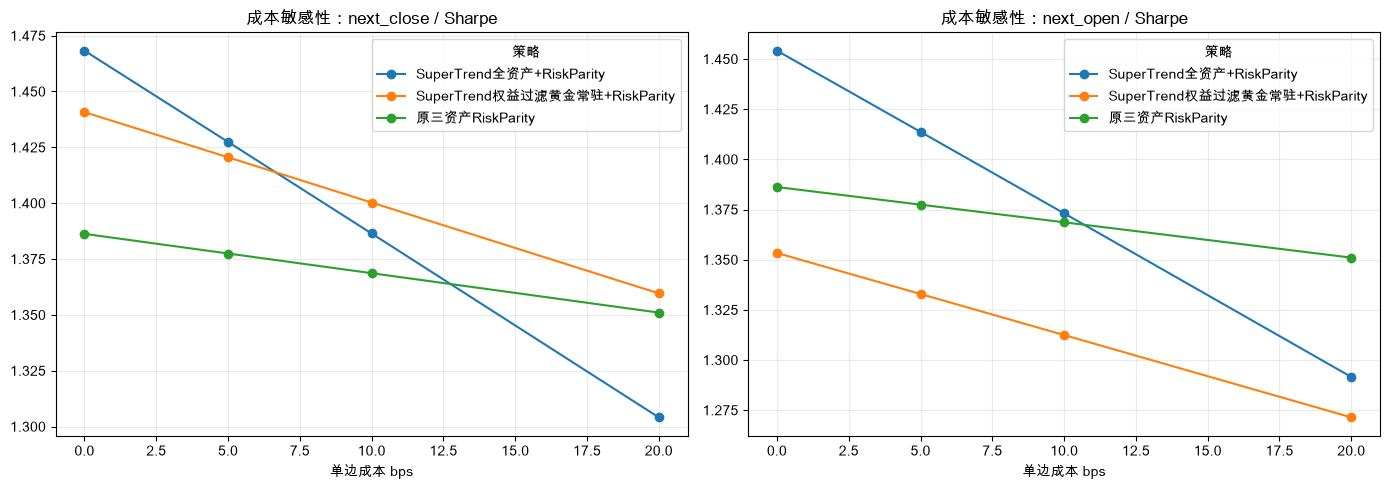

,execution,cost_bps,策略,累计收益,最大回撤,夏普,卡玛,年化换手,成本拖累,Alpha_vs_RP同成本
0,next_close,0,原三资产RiskParity,3.1864,-0.1353,1.3863,1.1862,1.9821,0.0000,0.0000
1,next_close,0,SuperTrend全资产+RiskParity,5.1478,-0.1838,1.4683,1.1308,10.9469,0.0000,1.9614
2,next_close,0,SuperTrend权益过滤黄金常驻+RiskParity,4.2629,-0.2169,1.4408,0.8689,5.0909,0.0000,1.0765
3,next_close,5,原三资产RiskParity,3.1467,-0.1368,1.3775,1.1649,1.9821,0.0095,0.0000
4,next_close,5,SuperTrend全资产+RiskParity,4.8324,-0.1898,1.4274,1.0599,10.9469,0.0527,1.6857
5,next_close,5,SuperTrend权益过滤黄金常驻+RiskParity,4.1357,-0.2169,1.4205,0.8550,5.0909,0.0245,0.9890
6,next_close,10,原三资产RiskParity,3.1074,-0.1383,1.3687,1.1441,1.9821,0.0191,0.0000
7,next_close,10,SuperTrend全资产+RiskParity,4.5331,-0.1959,1.3864,0.9937,10.9469,0.1053,1.4257
8,next_close,10,SuperTrend权益过滤黄金常驻+RiskParity,4.0115,-0.2169,1.4003,0.8411,5.0909,0.0490,0.9041
9,next_close,20,原三资产RiskParity,3.0298,-0.1412,1.3510,1.1038,1.9821,0.0381,0.0000


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for execution, ax in zip(["next_close", "next_open"], axes):
    sub = cost_sensitivity[cost_sensitivity["execution"] == execution]
    pivot = sub.pivot(index="cost_bps", columns="策略", values="夏普")
    pivot.plot(marker="o", ax=ax)
    ax.set_title(f"成本敏感性：{execution} / Sharpe")
    ax.set_xlabel("单边成本 bps")
    ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cost_execution_sensitivity.png", dpi=160)
plt.show()

cost_sensitivity[["execution", "cost_bps", "策略", "累计收益", "最大回撤", "夏普", "卡玛", "年化换手", "成本拖累", "Alpha_vs_RP同成本"]].round(4)


## 9. Robustness Scorecard

这个表将关键验证结果汇总成研究判断。重点不是机械打分，而是看 SuperTrend 是否在多数严苛检查下仍有解释力。


In [15]:
def bool_rate(series):
    return float(pd.Series(series).mean()) if len(series) else np.nan

score_rows = []
for candidate in ["SuperTrend全资产+RiskParity", "SuperTrend权益过滤黄金常驻+RiskParity"]:
    sub = rolling_scorecard[rolling_scorecard["候选"] == candidate]
    full = q5_metrics.loc[candidate]
    rp = q5_metrics.loc["原三资产RiskParity"]
    cost_next_close_10 = cost_sensitivity[(cost_sensitivity["execution"] == "next_close") & (cost_sensitivity["cost_bps"] == 10) & (cost_sensitivity["策略"] == candidate)].iloc[0]
    cost_next_open_10 = cost_sensitivity[(cost_sensitivity["execution"] == "next_open") & (cost_sensitivity["cost_bps"] == 10) & (cost_sensitivity["策略"] == candidate)].iloc[0]
    score_rows.append({
        "候选": candidate,
        "全样本累计收益跑赢": full["累计收益"] > rp["累计收益"],
        "全样本Sharpe跑赢": full["夏普"] > rp["夏普"],
        "全样本Calmar跑赢": full["卡玛"] > rp["卡玛"],
        "全样本回撤不深于RP": full["最大回撤"] >= rp["最大回撤"],
        "滚动窗口收益胜率": bool_rate(sub["收益跑赢RP"]),
        "滚动窗口Sharpe胜率": bool_rate(sub["Sharpe跑赢RP"]),
        "滚动窗口回撤不恶化率": bool_rate(sub["回撤不深于RP"]),
        "10bps_next_close仍有Alpha": cost_next_close_10["Alpha_vs_RP同成本"] > 0,
        "10bps_next_open仍有Alpha": cost_next_open_10["Alpha_vs_RP同成本"] > 0,
        "10bps_next_open_Sharpe": cost_next_open_10["夏普"],
        "10bps_next_open_最大回撤": cost_next_open_10["最大回撤"],
    })
robustness_scorecard = pd.DataFrame(score_rows)
robustness_scorecard.to_csv(OUTPUT_DIR / "robustness_scorecard.csv", encoding="utf-8-sig", index=False)
robustness_scorecard


,候选,全样本累计收益跑赢,全样本Sharpe跑赢,全样本Calmar跑赢,全样本回撤不深于RP,滚动窗口收益胜率,滚动窗口Sharpe胜率,滚动窗口回撤不恶化率,10bps_next_close仍有Alpha,10bps_next_open仍有Alpha,10bps_next_open_Sharpe,10bps_next_open_最大回撤
0,SuperTrend全资产+RiskParity,True,True,False,False,0.857143,0.571429,0.428571,True,True,1.373103,-0.154222
1,SuperTrend权益过滤黄金常驻+RiskParity,True,True,False,False,1.000000,1.000000,0.857143,True,True,1.312446,-0.216870


In [16]:
q8_decision_inputs = {
    "q7_sample_start": str(close.index[0].date()),
    "q7_sample_end": str(close.index[-1].date()),
    "full_sample_historical_best": q5_metrics["累计收益"].idxmax(),
    "full_sample_sharpe_best": q5_metrics["夏普"].idxmax(),
    "full_sample_calmar_best": q5_metrics["卡玛"].idxmax(),
    "default_st_rolling_return_win_rate": robustness_scorecard.loc[robustness_scorecard["候选"] == "SuperTrend全资产+RiskParity", "滚动窗口收益胜率"].iloc[0],
    "default_st_rolling_drawdown_nonworse_rate": robustness_scorecard.loc[robustness_scorecard["候选"] == "SuperTrend全资产+RiskParity", "滚动窗口回撤不恶化率"].iloc[0],
    "equity_only_rolling_return_win_rate": robustness_scorecard.loc[robustness_scorecard["候选"] == "SuperTrend权益过滤黄金常驻+RiskParity", "滚动窗口收益胜率"].iloc[0],
    "equity_only_rolling_drawdown_nonworse_rate": robustness_scorecard.loc[robustness_scorecard["候选"] == "SuperTrend权益过滤黄金常驻+RiskParity", "滚动窗口回撤不恶化率"].iloc[0],
    "train_best_atr": int(train_best["atr"]),
    "train_best_multiplier": float(train_best["multiplier"]),
    "default_test_sharpe_rank": int(default_row["test_夏普排名"]),
    "recommend_q8_btc": "yes_but_as_satellite_stress_test_not_core_replacement",
}
pd.Series(q8_decision_inputs).to_csv(OUTPUT_DIR / "q8_decision_inputs.csv", encoding="utf-8-sig")
pd.Series(q8_decision_inputs)


q7_sample_start                                                                      2016-06-21
q7_sample_end                                                                        2026-06-22
full_sample_historical_best                                            SuperTrend全资产+RiskParity
full_sample_sharpe_best                                                SuperTrend全资产+RiskParity
full_sample_calmar_best                                                          原三资产RiskParity
default_st_rolling_return_win_rate                                                     0.857143
default_st_rolling_drawdown_nonworse_rate                                              0.428571
equity_only_rolling_return_win_rate                                                         1.0
equity_only_rolling_drawdown_nonworse_rate                                             0.857143
train_best_atr                                                                               10
train_best_multiplier                   

## 10. Plain-Language Conclusion Template

- Historical best:
- Risk-adjusted best:
- Most structurally balanced:
- Main sample-period advantage:
- Main future failure mode:
- Q8 BTC decision:
- What to test next:
